In [1]:
import pandas as pd

col_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised", "root_shell",
    "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty"
]

url_train = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"
url_test  = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt"

df_train = pd.read_csv(url_train, names=col_names)
df_test  = pd.read_csv(url_test, names=col_names)

print("Treino:", df_train.shape)
print("Teste :", df_test.shape)

Treino: (125973, 43)
Teste : (22544, 43)


In [2]:
df_train = df_train.drop(columns=['difficulty'])
df_test = df_test.drop(columns=['difficulty'])

In [3]:
colunas_categoricas = ['protocol_type', 'service', 'flag']

n_train = len(df_train)
df_total = pd.concat([df_train, df_test], ignore_index=True)

df_total = pd.get_dummies(df_total, columns=colunas_categoricas, dtype=int)

df_train = df_total.iloc[:n_train].copy()
df_test = df_total.iloc[n_train:].copy()

print("Treino após One-Hot Encoding:", df_train.shape)
print("Teste após One-Hot Encoding :", df_test.shape)

Treino após One-Hot Encoding: (125973, 123)
Teste após One-Hot Encoding : (22544, 123)


In [4]:
X_train = df_train.drop(columns=['label'])
y_train = (df_train['label'] != 'normal').astype(int)

X_test = df_test.drop(columns=['label'])
y_test = (df_test['label'] != 'normal').astype(int)

print("y_train:\n", y_train.value_counts())
print("\ny_test:\n", y_test.value_counts())

y_train:
 label
0    67343
1    58630
Name: count, dtype: int64

y_test:
 label
1    12833
0     9711
Name: count, dtype: int64


In [5]:
from sklearn.preprocessing import StandardScaler

cols_one_hot = [col for col in X_train.columns if col.startswith(('protocol_type_', 'service_', 'flag_'))]
cols_numericas = [col for col in X_train.columns if col not in cols_one_hot]

scaler = StandardScaler()
X_train[cols_numericas] = scaler.fit_transform(X_train[cols_numericas])
X_test[cols_numericas] = scaler.transform(X_test[cols_numericas])

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

X_train shape: (125973, 122)
X_test shape : (22544, 122)


In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

X_train_t = torch.tensor(X_train.values, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)

X_test_t = torch.tensor(X_test.values, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).reshape(-1, 1)

train_ds = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)

print("X_train_t:", X_train_t.shape, "| y_train_t:", y_train_t.shape)
print("Total de batches de treino:", len(train_loader))

X_train_t: torch.Size([125973, 122]) | y_train_t: torch.Size([125973, 1])
Total de batches de treino: 493


In [14]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()
        self.hidden1 = nn.Linear(input_size, 128)
        self.hidden2 = nn.Linear(128, 64)
        self.output = nn.Linear(64, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.hidden1(x))
        x = self.relu(self.hidden2(x))
        x = self.output(x) 
        return x

In [15]:
model = MLP(input_size=X_train_t.shape[1])
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

MLP(
  (hidden1): Linear(in_features=122, out_features=128, bias=True)
  (hidden2): Linear(in_features=128, out_features=64, bias=True)
  (output): Linear(in_features=64, out_features=1, bias=True)
  (relu): ReLU()
)


Melhor val_loss: 0.0109 na época 27
Final (época 50) -> train_loss: 0.0056 | val_loss: 0.0185


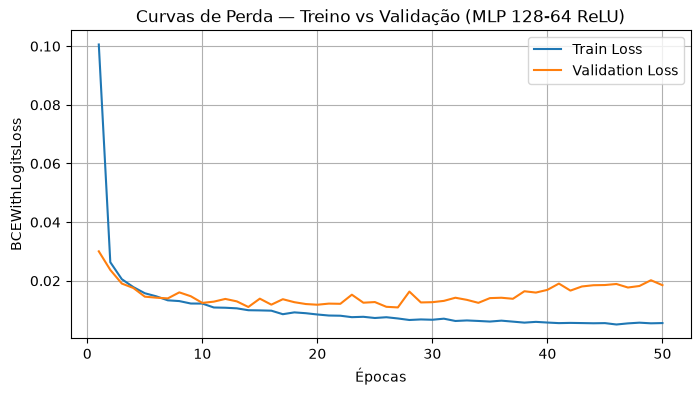

In [20]:
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import copy

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_t, y_train_t, test_size=0.2, shuffle=False
)

train_ds = TensorDataset(X_tr, y_tr)
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)

torch.manual_seed(42)
model = MLP(input_size=X_tr.shape[1])
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 50
train_loss_hist = []
val_loss_hist = []

best_val_loss = np.inf
best_weights = None
best_epoch = 0

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    epoch_train_loss = running_loss / len(train_loader)
    train_loss_hist.append(epoch_train_loss)

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val)
        val_loss = criterion(val_outputs, y_val).item()
    val_loss_hist.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1

print(f"Melhor val_loss: {best_val_loss:.4f} na época {best_epoch}")
print(f"Final (época 50) -> train_loss: {train_loss_hist[-1]:.4f} | val_loss: {val_loss_hist[-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_loss_hist, label='Train Loss')
plt.plot(range(1, epochs + 1), val_loss_hist, label='Validation Loss')
plt.xlabel('Épocas')
plt.ylabel('BCEWithLogitsLoss')
plt.title('Curvas de Perda — Treino vs Validação (MLP 128-64 ReLU)')
plt.legend()
plt.grid(True)
plt.show()

Topologia 2 (64 ReLU) -> Melhor val_loss: 0.0114 na época 40
Final (época 50)      -> train_loss: 0.0083 | val_loss: 0.0114


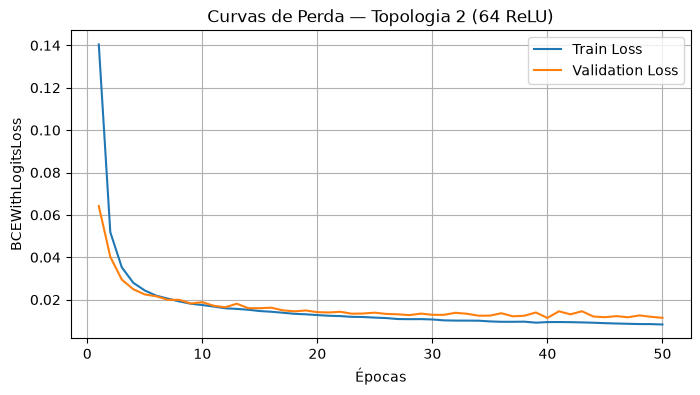

In [22]:
class MLP_Topologia2(nn.Module):
    def __init__(self, input_size):
        super(MLP_Topologia2, self).__init__()
        self.hidden1 = nn.Linear(input_size, 64)
        self.output = nn.Linear(64, 1)  
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.hidden1(x))
        x = self.output(x)
        return x

torch.manual_seed(42)
model_2 = MLP_Topologia2(input_size=X_tr.shape[1])
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_2.parameters(), lr=0.001)

epochs = 50
train_loss_2 = []
val_loss_2 = []

best_val_2 = np.inf
best_weights_2 = None
best_epoch_2 = 0

for epoch in range(epochs):
    model_2.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model_2(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    train_loss_2.append(running_loss / len(train_loader))

    model_2.eval()
    with torch.no_grad():
        val_outputs = model_2(X_val)
        v_loss = criterion(val_outputs, y_val).item()
    val_loss_2.append(v_loss)

    if v_loss < best_val_2:
        best_val_2 = v_loss
        best_weights_2 = copy.deepcopy(model_2.state_dict())
        best_epoch_2 = epoch + 1

print(f"Topologia 2 (64 ReLU) -> Melhor val_loss: {best_val_2:.4f} na época {best_epoch_2}")
print(f"Final (época 50)      -> train_loss: {train_loss_2[-1]:.4f} | val_loss: {val_loss_2[-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_loss_2, label='Train Loss')
plt.plot(range(1, epochs + 1), val_loss_2, label='Validation Loss')
plt.xlabel('Épocas')
plt.ylabel('BCEWithLogitsLoss')
plt.title('Curvas de Perda — Topologia 2 (64 ReLU)')
plt.legend()
plt.grid(True)
plt.show()

Topologia 3 (256-128-64 ReLU) -> Melhor val_loss: 0.0095 na época 17
Final (época 50)              -> train_loss: 0.0070 | val_loss: 0.0140


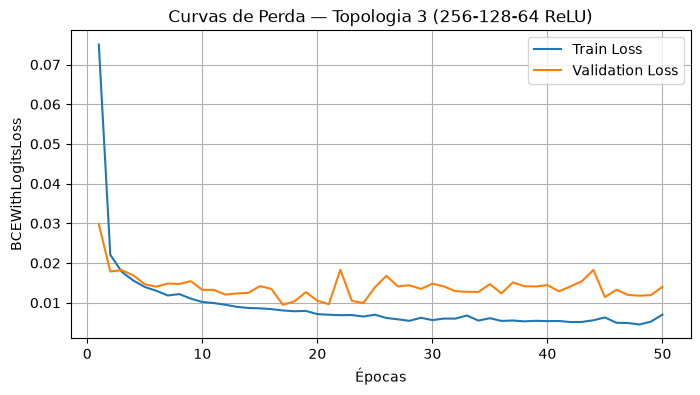

In [24]:
class MLP_Topologia3(nn.Module):
    def __init__(self, input_size):
        super(MLP_Topologia3, self).__init__()
        self.hidden1 = nn.Linear(input_size, 256)
        self.hidden2 = nn.Linear(256, 128)
        self.hidden3 = nn.Linear(128, 64)
        self.output = nn.Linear(64, 1)  
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.hidden1(x))
        x = self.relu(self.hidden2(x))
        x = self.relu(self.hidden3(x))
        x = self.output(x)
        return x

torch.manual_seed(42)
model_3 = MLP_Topologia3(input_size=X_tr.shape[1])
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_3.parameters(), lr=0.001)

epochs = 50
train_loss_3 = []
val_loss_3 = []

best_val_3 = np.inf
best_weights_3 = None
best_epoch_3 = 0

for epoch in range(epochs):
    model_3.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model_3(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    train_loss_3.append(running_loss / len(train_loader))

    model_3.eval()
    with torch.no_grad():
        val_outputs = model_3(X_val)
        v_loss = criterion(val_outputs, y_val).item()
    val_loss_3.append(v_loss)

    if v_loss < best_val_3:
        best_val_3 = v_loss
        best_weights_3 = copy.deepcopy(model_3.state_dict())
        best_epoch_3 = epoch + 1

print(f"Topologia 3 (256-128-64 ReLU) -> Melhor val_loss: {best_val_3:.4f} na época {best_epoch_3}")
print(f"Final (época 50)              -> train_loss: {train_loss_3[-1]:.4f} | val_loss: {val_loss_3[-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_loss_3, label='Train Loss')
plt.plot(range(1, epochs + 1), val_loss_3, label='Validation Loss')
plt.xlabel('Épocas')
plt.ylabel('BCEWithLogitsLoss')
plt.title('Curvas de Perda — Topologia 3 (256-128-64 ReLU)')
plt.legend()
plt.grid(True)
plt.show()

Topologia 4 (128-64 Tanh) -> Melhor val_loss: 0.0094 na época 50
Final (época 50)          -> train_loss: 0.0055 | val_loss: 0.0094


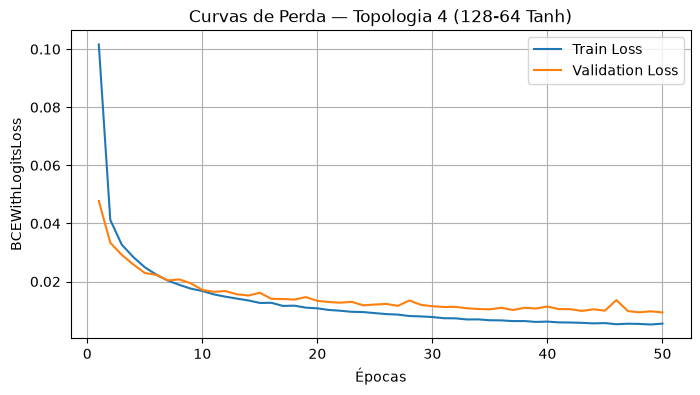

In [28]:
class MLP_Topologia4(nn.Module):
    def __init__(self, input_size):
        super(MLP_Topologia4, self).__init__()
        self.hidden1 = nn.Linear(input_size, 128)
        self.hidden2 = nn.Linear(128, 64)
        self.output = nn.Linear(64, 1) 
        self.tanh = nn.Tanh()           

    def forward(self, x):
        x = self.tanh(self.hidden1(x))
        x = self.tanh(self.hidden2(x))
        x = self.output(x)
        return x

class MLP_Topologia4(nn.Module):
    def __init__(self, input_size):
        super(MLP_Topologia4, self).__init__()
        self.hidden1 = nn.Linear(input_size, 128)
        self.hidden2 = nn.Linear(128, 64)
        self.output = nn.Linear(64, 1)  
        self.tanh = nn.Tanh()

    def forward(self, x):
        x = self.tanh(self.hidden1(x))
        x = self.tanh(self.hidden2(x))
        x = self.output(x)
        return x

torch.manual_seed(42)
model_4 = MLP_Topologia4(input_size=X_tr.shape[1])
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_4.parameters(), lr=0.001)

epochs = 50
train_loss_4 = []
val_loss_4 = []

best_val_4 = np.inf
best_weights_4 = None
best_epoch_4 = 0

for epoch in range(epochs):
    model_4.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model_4(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    train_loss_4.append(running_loss / len(train_loader))

    model_4.eval()
    with torch.no_grad():
        val_outputs = model_4(X_val)
        v_loss = criterion(val_outputs, y_val).item()
    val_loss_4.append(v_loss)

    if v_loss < best_val_4:
        best_val_4 = v_loss
        best_weights_4 = copy.deepcopy(model_4.state_dict())
        best_epoch_4 = epoch + 1

print(f"Topologia 4 (128-64 Tanh) -> Melhor val_loss: {best_val_4:.4f} na época {best_epoch_4}")
print(f"Final (época 50)          -> train_loss: {train_loss_4[-1]:.4f} | val_loss: {val_loss_4[-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_loss_4, label='Train Loss')
plt.plot(range(1, epochs + 1), val_loss_4, label='Validation Loss')
plt.xlabel('Épocas')
plt.ylabel('BCEWithLogitsLoss')
plt.title('Curvas de Perda — Topologia 4 (128-64 Tanh)')
plt.legend()
plt.grid(True)
plt.show()

Topologia 5 (256-128-64 Tanh) -> Melhor val_loss: 0.0091 na época 41
Final (época 50)              -> train_loss: 0.0052 | val_loss: 0.0098


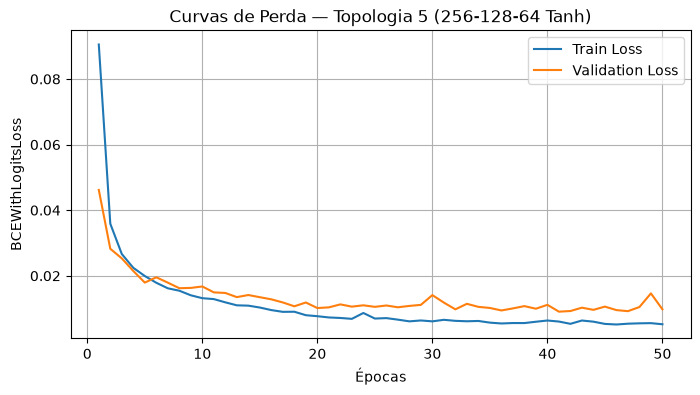

In [29]:
class MLP_Topologia5(nn.Module):
    def __init__(self, input_size):
        super(MLP_Topologia5, self).__init__()
        self.hidden1 = nn.Linear(input_size, 256)
        self.hidden2 = nn.Linear(256, 128)
        self.hidden3 = nn.Linear(128, 64)
        self.output = nn.Linear(64, 1)  
        self.tanh = nn.Tanh()

    def forward(self, x):
        x = self.tanh(self.hidden1(x))
        x = self.tanh(self.hidden2(x))
        x = self.tanh(self.hidden3(x))
        x = self.output(x)
        return x

torch.manual_seed(42)
model_5 = MLP_Topologia5(input_size=X_tr.shape[1])
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_5.parameters(), lr=0.001)

epochs = 50
train_loss_5 = []
val_loss_5 = []

best_val_5 = np.inf
best_weights_5 = None
best_epoch_5 = 0

for epoch in range(epochs):
    model_5.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model_5(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    train_loss_5.append(running_loss / len(train_loader))

    model_5.eval()
    with torch.no_grad():
        val_outputs = model_5(X_val)
        v_loss = criterion(val_outputs, y_val).item()
    val_loss_5.append(v_loss)

    if v_loss < best_val_5:
        best_val_5 = v_loss
        best_weights_5 = copy.deepcopy(model_5.state_dict())
        best_epoch_5 = epoch + 1

print(f"Topologia 5 (256-128-64 Tanh) -> Melhor val_loss: {best_val_5:.4f} na época {best_epoch_5}")
print(f"Final (época 50)              -> train_loss: {train_loss_5[-1]:.4f} | val_loss: {val_loss_5[-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_loss_5, label='Train Loss')
plt.plot(range(1, epochs + 1), val_loss_5, label='Validation Loss')
plt.xlabel('Épocas')
plt.ylabel('BCEWithLogitsLoss')
plt.title('Curvas de Perda — Topologia 5 (256-128-64 Tanh)')
plt.legend()
plt.grid(True)
plt.show()

In [30]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

model_5.load_state_dict(best_weights_5)
model_5.eval()

with torch.no_grad():
    logits_test = model_5(X_test_t)
    probs_test = torch.sigmoid(logits_test)
    y_pred_test = (probs_test >= 0.5).int().numpy()

y_true_test = y_test_t.int().numpy()

cm = confusion_matrix(y_true_test, y_pred_test)
acc = accuracy_score(y_true_test, y_pred_test)
prec = precision_score(y_true_test, y_pred_test)
rec = recall_score(y_true_test, y_pred_test)
f1 = f1_score(y_true_test, y_pred_test)

print("Matriz de Confusão (Teste):")
print(cm)
print(f"\nAcurácia : {acc:.4f}")
print(f"Precisão : {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")

Matriz de Confusão (Teste):
[[9158  553]
 [4468 8365]]

Acurácia : 0.7773
Precisão : 0.9380
Recall   : 0.6518
F1-Score : 0.7692
